Butterworth Filter Coefficients:
Numerator: [1.29607191e-05 5.18428766e-05 7.77643148e-05 5.18428766e-05
 1.29607191e-05]
Denominator: [ 1.         -3.67388572  5.07378356 -3.12116011  0.72146964]


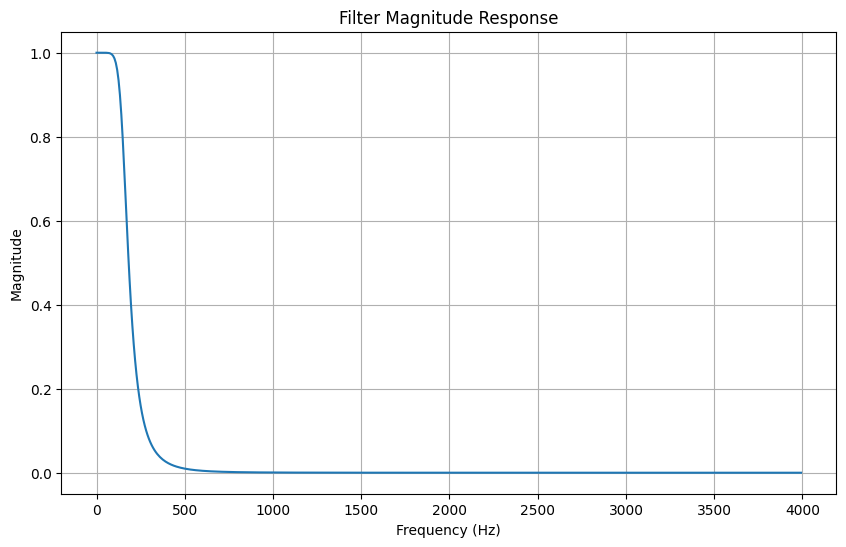

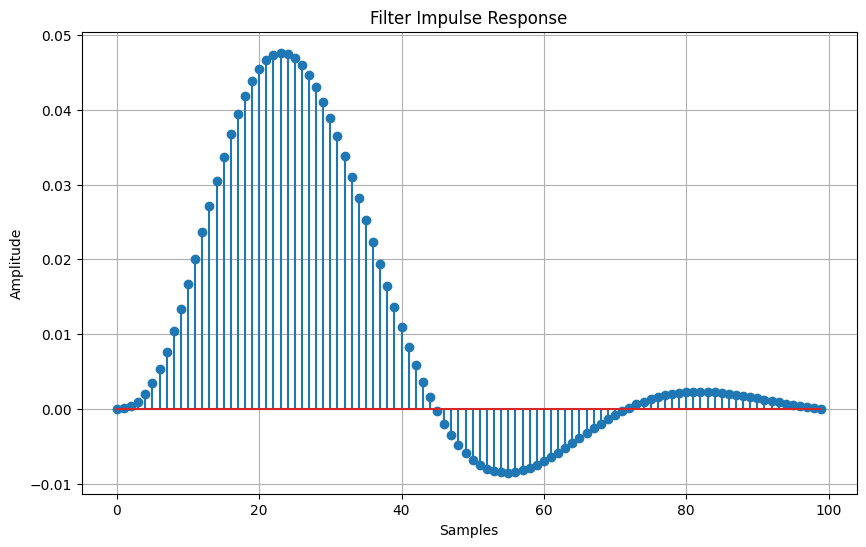

Chebyshev Filter Coefficients:
Numerator: [5.04743397e-06 2.01897359e-05 3.02846038e-05 2.01897359e-05
 5.04743397e-06]
Denominator: [ 1.         -3.83541526  5.53394882 -3.55962935  0.86118134]


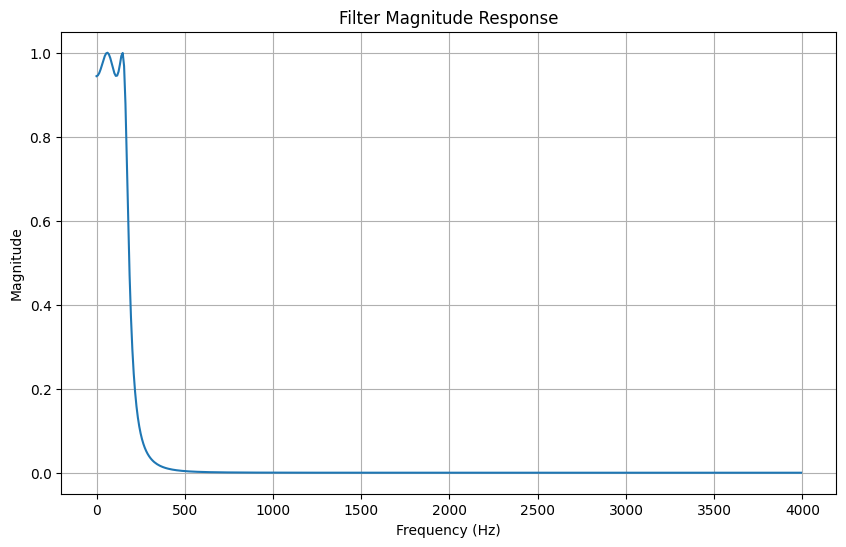

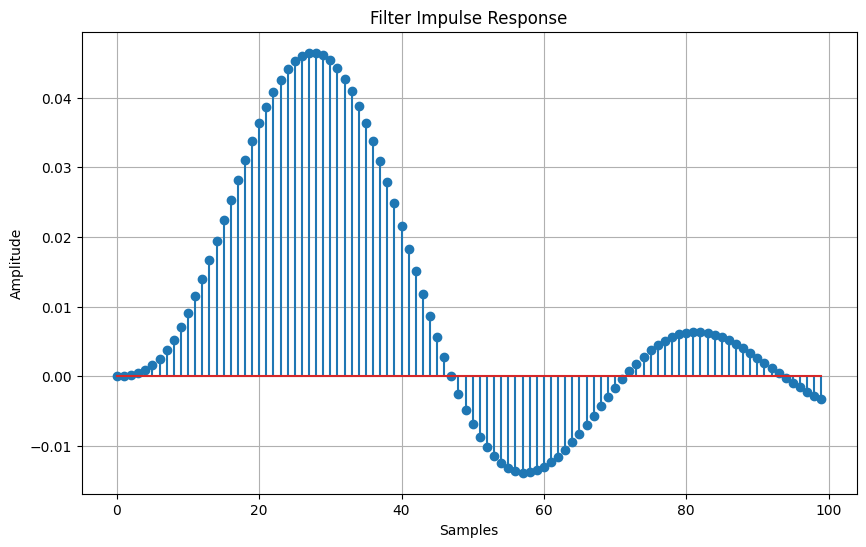

Filter coefficients saved at: filter_coefficients.txt


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1, lfilter

# Design Butterworth filter
def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):

    # Design analog Butterworth filter
    analog_b, analog_a = butter(
        filter_order, cutoff_frequency, analog=True, btype="low"
    )

    # Convert analog filter to digital filter
    digital_b, digital_a = bilinear(
        analog_b, analog_a, fs=sampling_frequency
    )

    return digital_b, digital_a


# Design Chebyshev filter
def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):

    # Design analog Chebyshev filter
    analog_b, analog_a = cheby1(
        filter_order, ripple, cutoff_frequency, analog=True, btype="low"
    )

    # Convert analog filter to digital filter
    digital_b, digital_a = bilinear(
        analog_b, analog_a, fs=sampling_frequency
    )

    return digital_b, digital_a


# Plot filter response
def plot_filter_response(digital_b, digital_a, sampling_frequency):

    # Calculate frequency response
    frequency, magnitude_response = freqz(
        digital_b, digital_a, fs=sampling_frequency
    )

    # Plot magnitude response
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, np.abs(magnitude_response))
    plt.title("Filter Magnitude Response")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.grid(True)
    plt.show()

    # Create an impulse signal
    impulse = np.zeros(100)
    impulse[0] = 1

    # Calculate the actual impulse response
    impulse_response = lfilter(digital_b, digital_a, impulse)

    # Plot impulse response
    plt.figure(figsize=(10, 6))
    plt.stem(impulse_response)
    plt.title("Filter Impulse Response")
    plt.xlabel("Samples")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()


# Filter specifications
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5

# Design and plot Butterworth filter
butter_b, butter_a = design_butterworth_filter(
    filter_order, cutoff_frequency, sampling_frequency
)

print("Butterworth Filter Coefficients:")
print("Numerator:", butter_b)
print("Denominator:", butter_a)

plot_filter_response(butter_b, butter_a, sampling_frequency)

# Design and plot Chebyshev filter
cheby_b, cheby_a = design_chebyshev_filter(
    filter_order, cutoff_frequency, sampling_frequency, ripple
)

print("Chebyshev Filter Coefficients:")
print("Numerator:", cheby_b)
print("Denominator:", cheby_a)

plot_filter_response(cheby_b, cheby_a, sampling_frequency)

# Save both filters' coefficients
filter_path = "filter_coefficients.txt"

np.savetxt(
    filter_path,
    np.vstack((
        np.pad(butter_b, (0, max(len(butter_b), len(butter_a)) - len(butter_b))),
        np.pad(butter_a, (0, max(len(butter_b), len(butter_a)) - len(butter_a))),
        np.pad(cheby_b, (0, max(len(cheby_b), len(cheby_a)) - len(cheby_b))),
        np.pad(cheby_a, (0, max(len(cheby_b), len(cheby_a)) - len(cheby_a)))
    )),
    delimiter=","
)

print("Filter coefficients saved at:", filter_path)

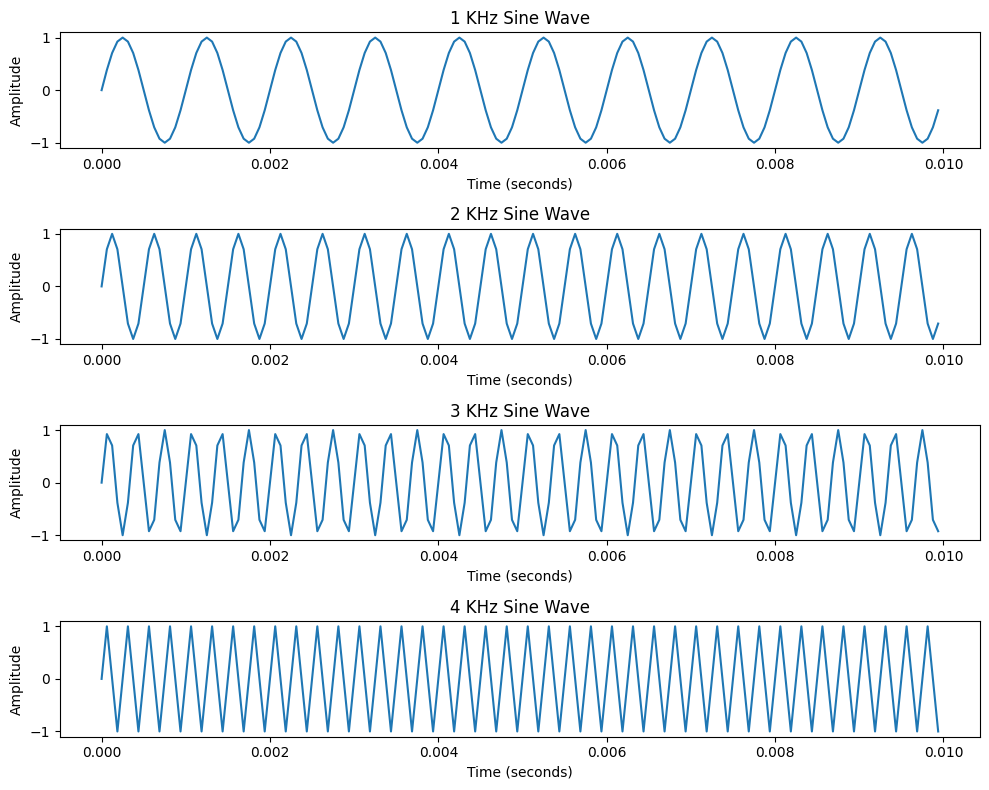

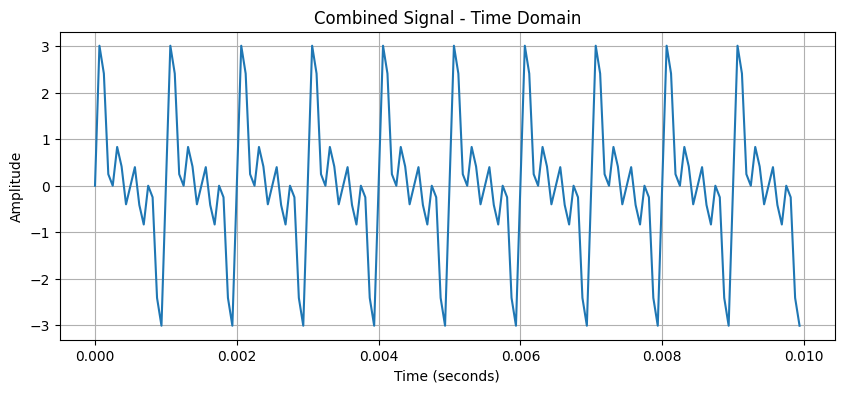

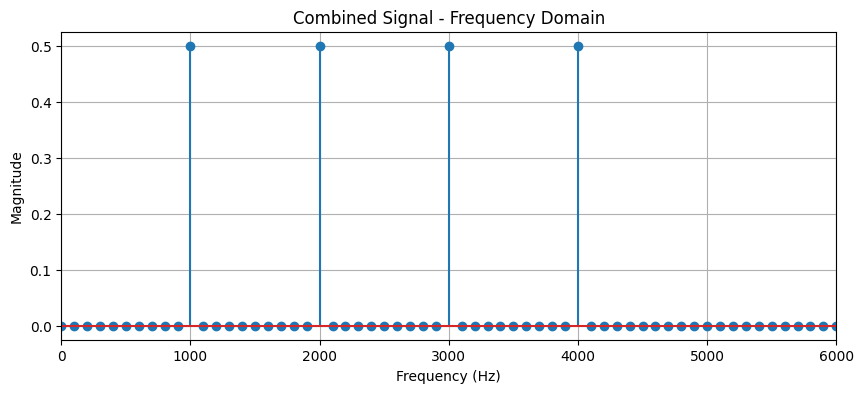

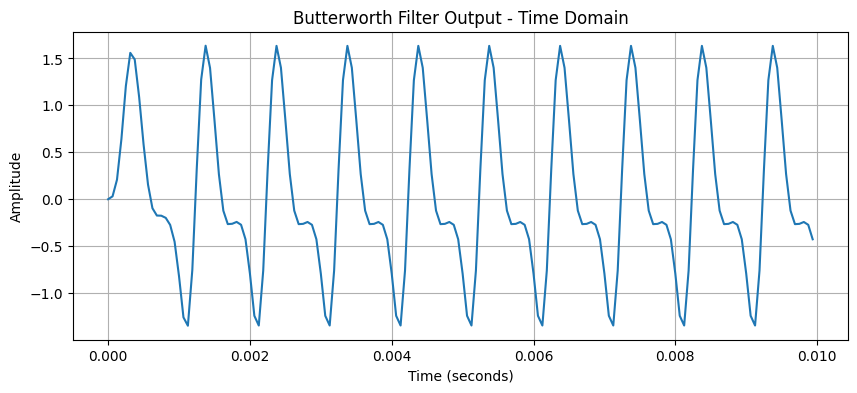

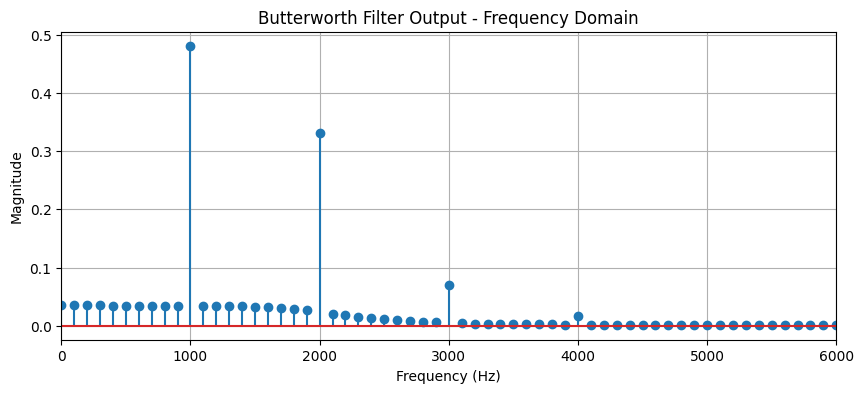

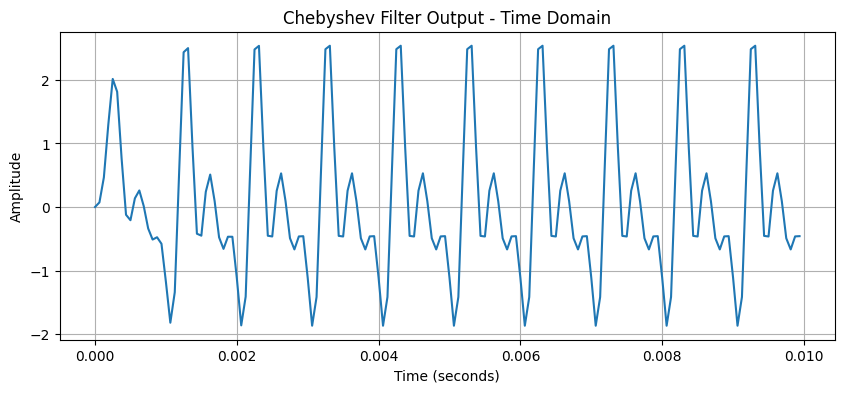

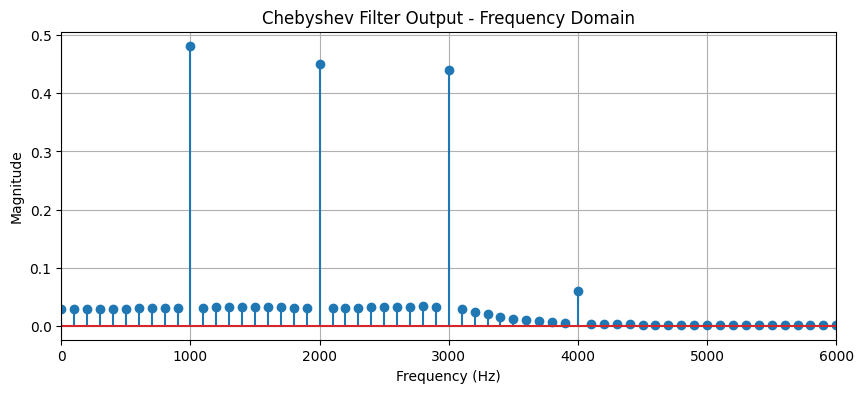

DSP task completed successfully.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, cheby1, freqz, lfilter

# Sampling frequency
fs = 16000

# Generate time axis for 0.01 seconds
t = np.arange(0, 0.01, 1/fs)

# Generate four sine waves
s1 = np.sin(2 * np.pi * 1000 * t)
s2 = np.sin(2 * np.pi * 2000 * t)
s3 = np.sin(2 * np.pi * 3000 * t)
s4 = np.sin(2 * np.pi * 4000 * t)

# Plot all four individual signals
plt.figure(figsize=(10, 8))

plt.subplot(4, 1, 1)
plt.plot(t, s1)
plt.title("1 KHz Sine Wave")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.subplot(4, 1, 2)
plt.plot(t, s2)
plt.title("2 KHz Sine Wave")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.subplot(4, 1, 3)
plt.plot(t, s3)
plt.title("3 KHz Sine Wave")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.subplot(4, 1, 4)
plt.plot(t, s4)
plt.title("4 KHz Sine Wave")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()


# Add all four signals
combined_signal = s1 + s2 + s3 + s4


# Function to plot time and frequency domains
def plot_signal(signal, title):

    # Time domain plot
    plt.figure(figsize=(10, 4))
    plt.plot(t, signal)
    plt.title(title + " - Time Domain")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

    # Frequency domain using FFT
    fft_result = np.fft.rfft(signal)
    frequencies = np.fft.rfftfreq(len(signal), 1/fs)
    magnitude = np.abs(fft_result) / len(signal)

    plt.figure(figsize=(10, 4))
    plt.stem(frequencies, magnitude)
    plt.title(title + " - Frequency Domain")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.xlim(0, 6000)
    plt.grid(True)
    plt.show()


# Plot combined signal
plot_signal(combined_signal, "Combined Signal")


# Butterworth low-pass filter with 2 KHz cutoff
butter_b, butter_a = butter(
    4, 2000, btype="low", fs=fs
)

butter_output = lfilter(
    butter_b, butter_a, combined_signal
)

# Plot Butterworth output
plot_signal(butter_output, "Butterworth Filter Output")


# Chebyshev Type I low-pass filter with 3 KHz cutoff
cheby_b, cheby_a = cheby1(
    4, 0.5, 3000, btype="low", fs=fs
)

cheby_output = lfilter(
    cheby_b, cheby_a, combined_signal
)

# Plot Chebyshev output
plot_signal(cheby_output, "Chebyshev Filter Output")


print("DSP task completed successfully.")